In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score)

diabetes = pd.read_csv("/diabetes_binary_classification_data.csv")

diabetes.head()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


Missing values: 0
Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64
Diabetes_binary
0.0    0.861
1.0    0.139
Name: proportion, dtype: float64


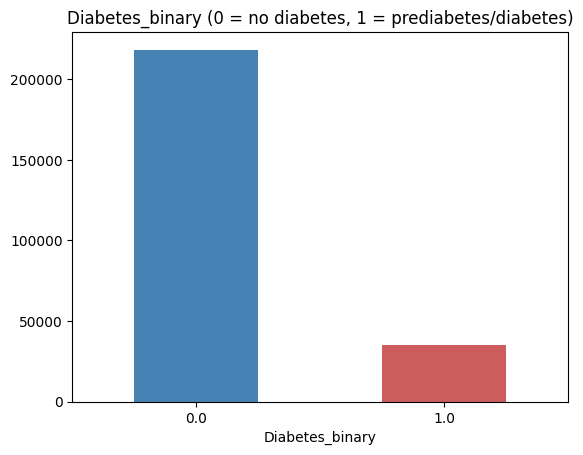

In [15]:
# CELLULE 2 - X, y et classes
print("Missing values:", diabetes.isna().sum().sum())

X = diabetes.drop(columns="Diabetes_binary")
y = diabetes["Diabetes_binary"]

print(y.value_counts())
print(y.value_counts(normalize=True).round(3))

y.value_counts().plot(kind="bar", color=["steelblue", "indianred"])
plt.title("Diabetes_binary (0 = no diabetes, 1 = prediabetes/diabetes)")
plt.xticks(rotation=0)
plt.show()

In [16]:
# CELLULE 3 : Types de features
binary = ["HighBP","HighChol","CholCheck","Smoker","Stroke","HeartDiseaseorAttack","PhysActivity",
          "Fruits","Veggies","HvyAlcoholConsump","AnyHealthcare","NoDocbcCost","DiffWalk","Sex"]
ordinal = ["GenHlth","Age","Education","Income"]
numeric = ["BMI","MentHlth","PhysHlth"]

print("Numerical:", numeric)
print("Binary:", binary)
print("Ordinal:", ordinal)

Numerical: ['BMI', 'MentHlth', 'PhysHlth']
Binary: ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
Ordinal: ['GenHlth', 'Age', 'Education', 'Income']


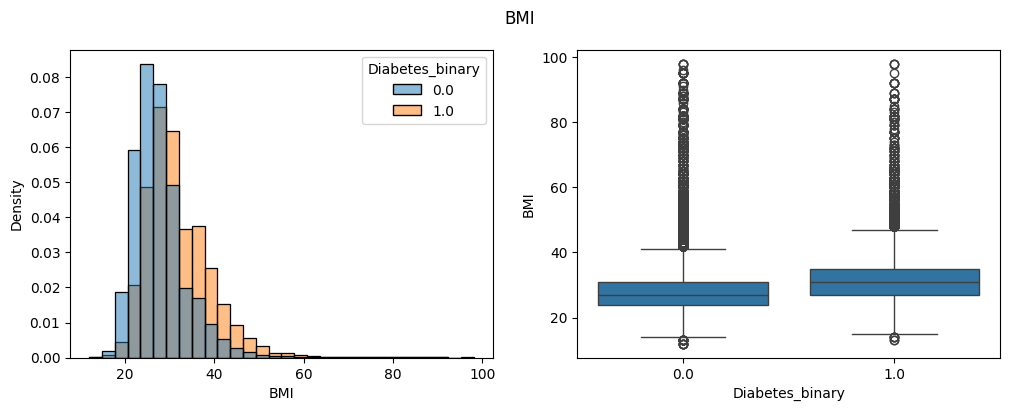

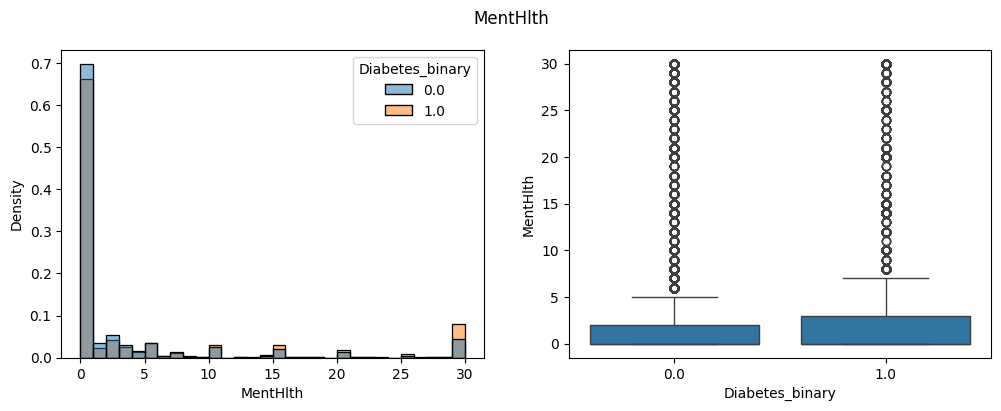

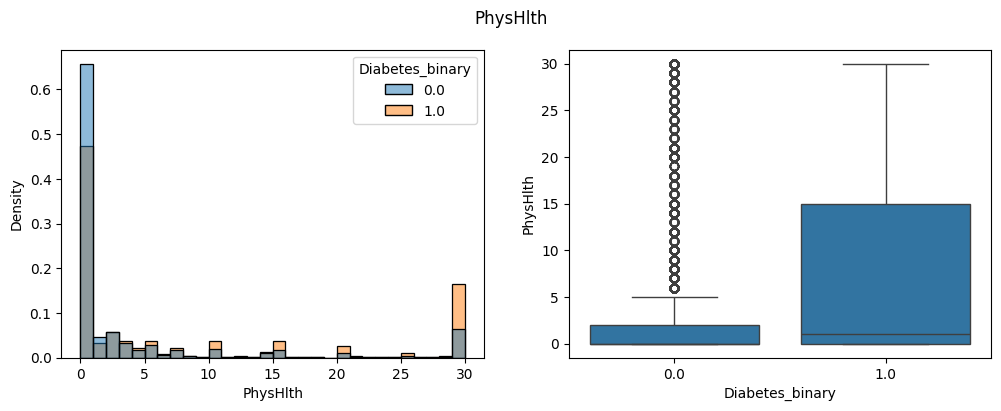

                  BMI  MentHlth  PhysHlth
Diabetes_binary                          
0.0              27.0       0.0       0.0
1.0              31.0       0.0       1.0


In [17]:
# CELLULE 4 : Step 2 : Numériques par classe
for col in numeric:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(data=diabetes, x=col, hue="Diabetes_binary", bins=30,
                 stat="density", common_norm=False, ax=axes[0])
    sns.boxplot(data=diabetes, x="Diabetes_binary", y=col, ax=axes[1])
    plt.suptitle(col)
    plt.show()

print(diabetes.groupby("Diabetes_binary")[numeric].median())

                      % diabetes when 0  % diabetes when 1
HighBP                              6.0               24.4
HighChol                            8.0               22.0
CholCheck                           2.5               14.4
Smoker                             12.1               16.3
Stroke                             13.2               31.8
HeartDiseaseorAttack               12.0               33.0
PhysActivity                       21.1               11.6
Fruits                             15.8               12.9
Veggies                            18.0               13.0
HvyAlcoholConsump                  14.4                5.8
AnyHealthcare                      11.5               14.1
NoDocbcCost                        13.6               17.5
DiffWalk                           10.5               30.7
Sex                                13.0               15.2


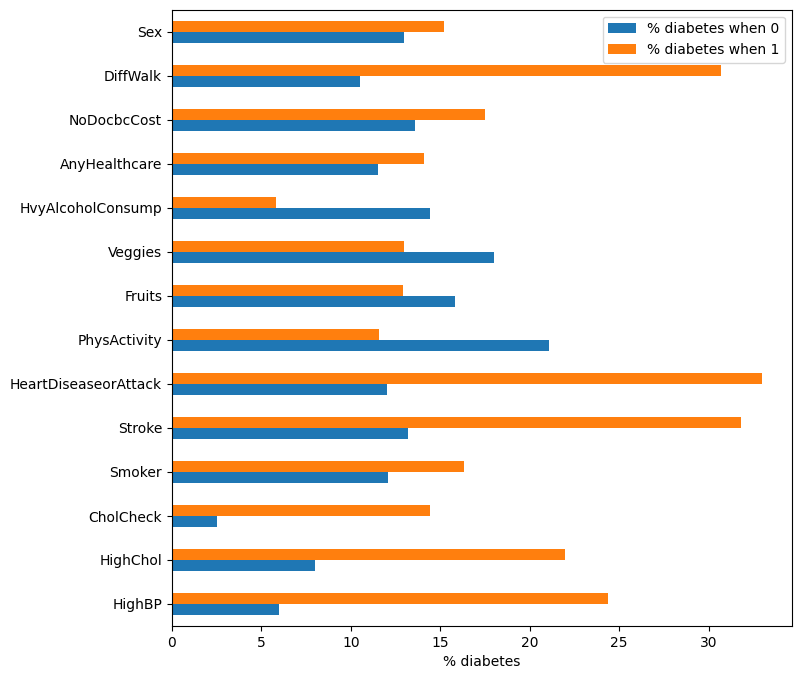

In [18]:
# CELLULE 5 : Step 2 : Binaires, % de diabétiques si 0 ou si 1
binary_table = pd.DataFrame({
    col: pd.crosstab(diabetes[col], diabetes["Diabetes_binary"], normalize="index")[1] * 100
    for col in binary
}).T.round(1)
binary_table.columns = ["% diabetes when 0", "% diabetes when 1"]
print(binary_table)

binary_table.plot(kind="barh", figsize=(8, 8))
plt.xlabel("% diabetes")
plt.show()

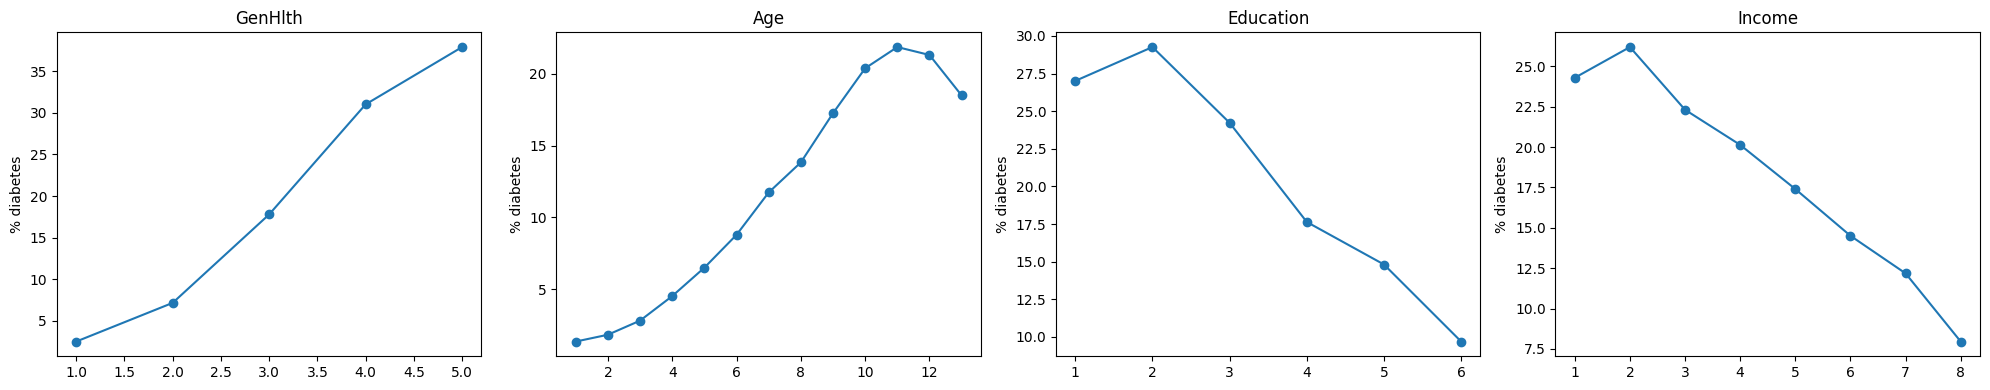

GenHlth [2.5, 7.2, 17.8, 31.0, 37.9]
Age [1.4, 1.8, 2.8, 4.5, 6.5, 8.8, 11.7, 13.8, 17.2, 20.4, 21.8, 21.3, 18.5]
Education [27.0, 29.3, 24.2, 17.6, 14.8, 9.7]
Income [24.3, 26.2, 22.3, 20.1, 17.4, 14.5, 12.2, 8.0]


In [19]:
# CELLULE 6 : Step 2 : Ordinales, % de diabétiques par catégorie
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, ordinal):
    taux = diabetes.groupby(col)["Diabetes_binary"].mean() * 100
    ax.plot(taux.index, taux.values, marker="o")
    ax.set_title(col)
    ax.set_ylabel("% diabetes")
plt.tight_layout()
plt.show()

for col in ordinal:
    print(col, (diabetes.groupby(col)["Diabetes_binary"].mean() * 100).round(1).tolist())

In [20]:
# CELLULE 7 : Step 3 : TRAIN / TEST
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train size:", len(X_train), "| Test size:", len(X_test))
print("% class 1 — Train:", round(y_train.mean() * 100, 1), "| Test:", round(y_test.mean() * 100, 1))

Train size: 202944 | Test size: 50736
% class 1 — Train: 13.9 | Test: 13.9


In [21]:
# CELLULE 8 : Step 4 : Préparation
ordinal_categories = [[1,2,3,4,5], list(range(1,14)), list(range(1,7)), list(range(1,9))]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("ord", OrdinalEncoder(categories=ordinal_categories), ordinal),
    ("bin", "passthrough", binary),
])

print("Scaled:", numeric)
print("Ordinal encoded:", ordinal)
print("Kept 0/1:", binary)

Scaled: ['BMI', 'MentHlth', 'PhysHlth']
Ordinal encoded: ['GenHlth', 'Age', 'Education', 'Income']
Kept 0/1: ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']


In [22]:
# CELLULE 9 : Step 5 : Logistic Regression
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000)),
])
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("Predicted classes:", y_pred[:10])
print("Probabilities:", y_proba[:10].round(3))

Predicted classes: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Probabilities: [0.154 0.292 0.02  0.033 0.481 0.119 0.029 0.011 0.053 0.167]


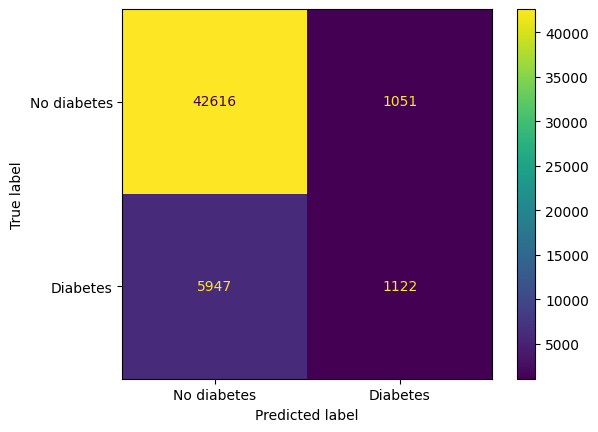

Accuracy : 0.862
Precision: 0.516
Recall   : 0.159
F1       : 0.243
Accuracy if always 0: 0.861


In [23]:
# CELLULE 10 : Step 6 : Évaluation (seuil 0.50)
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["No diabetes", "Diabetes"]).plot(values_format="d")
plt.show()

print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))
print("F1       :", round(f1_score(y_test, y_pred), 3))
print("Accuracy if always 0:", round((y_test == 0).mean(), 3))

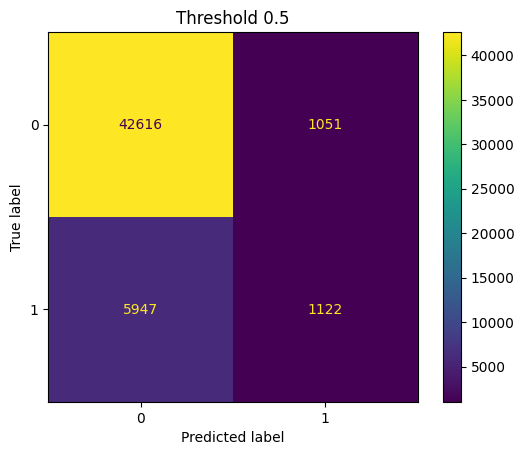

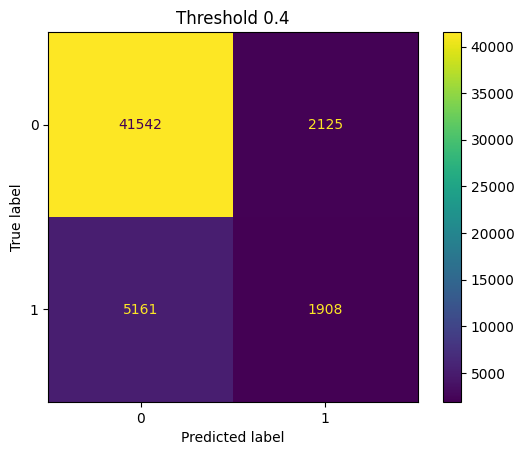

   Threshold  Accuracy  Precision  Recall     F1    FP    FN
0        0.5     0.862      0.516   0.159  0.243  1051  5947
1        0.4     0.856      0.473   0.270  0.344  2125  5161


In [24]:
# CELLULE 11 : Step 7 : Seuil 0.50 vs 0.40
rows = []
for t in [0.50, 0.40]:
    pred = (y_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"Threshold": t,
                 "Accuracy": round(accuracy_score(y_test, pred), 3),
                 "Precision": round(precision_score(y_test, pred), 3),
                 "Recall": round(recall_score(y_test, pred), 3),
                 "F1": round(f1_score(y_test, pred), 3),
                 "FP": fp, "FN": fn})
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot(values_format="d")
    plt.title(f"Threshold {t}")
    plt.show()

print(pd.DataFrame(rows))